This script uses a log-demand model and calculus to demonstrate revenue maximization. A price elasticity breakout is also included.

R(x)=p(x) * x  



\(R(x)\): Total revenue as a function of quantity sold.



\(p(x)\): Price per unit as a function of quantity sold.



\(x\): Quantity of units sold.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import datetime as dt
from sklearn.linear_model import LinearRegression

from pathlib import Path
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

project_dir = Path.cwd()
data_dir = project_dir / 'Raw Data'
results_dict = {}

# Get data

In [2]:
# load single-store sales data
sales_long = pd.read_csv(
    data_dir / 'sales_long.csv',
    parse_dates=['date'],
    low_memory=False
)

# recall the level of this dataset
# i.e. a single store with many items over many dates
sales_long.groupby(['store_id','date','cat_id'])[['item_id']].nunique().head()

item_id
store_id date       cat_id            
CA_1     2011-01-29 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-01-30 FOODS         1437
                    HOBBIES        565

In [3]:
# prepare data
df = sales_long[['item_id', 'date', 'units_sold', 'sell_price']].copy()
df['date'] = pd.to_datetime(df['date'])
df = df.dropna(subset=['item_id', 'date', 'units_sold', 'sell_price'])
df = df[(df['sell_price'] > 0) & (df['units_sold'] >= 0)]

# Choose a candidate item to optimize

In [4]:
# choose a product with enough observations and price variation
candidates = (
    df.groupby('item_id')
    .agg(
        observations=('units_sold', 'size'),
        price_levels=('sell_price', 'nunique'),
        average_sales=('units_sold', 'mean')
    )
)
candidates = candidates[
    (candidates['observations'] >= 180) & # about 6 months
    (candidates['price_levels'] >= 5) &
    (candidates['average_sales'] > 0)
]

if candidates.empty:
    raise ValueError("No product has enough observations and price variation.")

In [5]:
item = candidates.sort_values(
    ['price_levels', 'observations'], ascending=False
).index[0]

print(f"you chose: {item}")

product = df[df['item_id'] == item].copy()
product['month'] = product['date'].dt.month.astype(str)
product['weekday'] = product['date'].dt.dayofweek.astype(str)

you chose: FOODS_1_095


In [6]:
product.head()

,item_id,date,units_sold,sell_price,month,weekday
1705,FOODS_1_095,2011-01-29,1,2.66,1,5
4754,FOODS_1_095,2011-01-30,1,2.66,1,6
7803,FOODS_1_095,2011-01-31,2,2.66,1,0
10852,FOODS_1_095,2011-02-01,0,2.66,2,1
13901,FOODS_1_095,2011-02-02,1,2.66,2,2


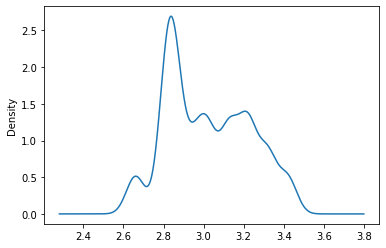

In [7]:
product['sell_price'].plot(kind='kde')

# Model demand with log-demand model
Fit a linear model to the natural log of historical demand.  
Taking the natural log alters the scale of the data, stabilizing it and reducing skew.

In [8]:
# fit a log-demand model with calendar controls

# log-transform price to model proportional price changes
X = pd.concat([
    np.log(product[['sell_price']]).rename(
        columns={'sell_price': 'log_price'}
    ),

    # control for monthly and weekly demand patterns
    pd.get_dummies(product[['month', 'weekday']], dtype=float)
], axis=1)

# log-transform demand
y = np.log1p(product['units_sold'])

# fit linear regression
model = LinearRegression().fit(X, y)

In [9]:
# test plausible prices within the observed range
prices = np.linspace(
    product['sell_price'].quantile(0.10),
    product['sell_price'].quantile(0.90),
    50
)

# predict demand at each candidate price
predictions = []

for price in prices:
    test = X.copy()
    test['log_price'] = np.log(price)

    predicted_units = np.expm1(model.predict(test)).mean() # <----------------------- model fit
    predictions.append(max(0, predicted_units))

results = pd.DataFrame({
    'price': prices,
    'predicted_units': predictions
})

results['predicted_revenue'] = (
    results['price'] * results['predicted_units']
)

best = results.loc[results['predicted_revenue'].idxmax()]
current_price = product['sell_price'].median()

print(f"Product: {item}")
print(f"Median historical price: ${current_price:.2f}")
print(f"Estimated revenue-maximizing price: ${best['price']:.2f}")
print(f"Predicted units per day: {best['predicted_units']:.2f}")
print(f"Predicted revenue per day: ${best['predicted_revenue']:.2f}")
      
results_dict['Log-Demand'] = {
    'median_historical_price': current_price,
    'revenue_maximizing_price': best['price'],
    'predicted_units_per_day': best['predicted_units'],
    'predicted_revenue_per_day': best['predicted_revenue']
}      

Product: FOODS_1_095
Median historical price: $3.02
Estimated revenue-maximizing price: $2.83
Predicted units per day: 0.15
Predicted revenue per day: $0.44


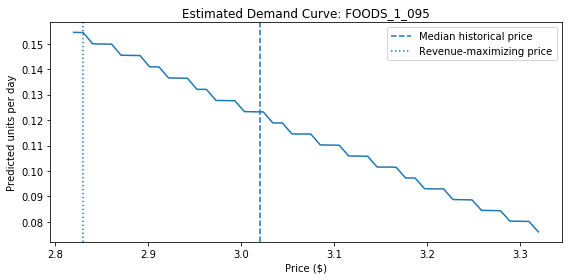

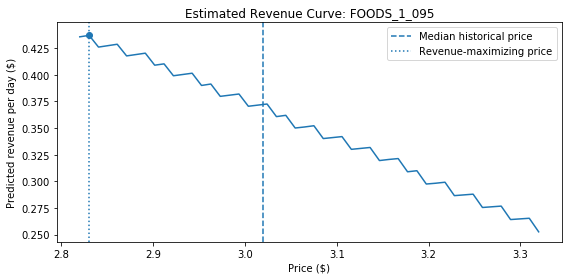

In [10]:
# plot estimated demand
plt.figure(figsize=(8, 4))
plt.plot(
    results['price'].to_numpy(),
    results['predicted_units'].to_numpy()
)
plt.axvline(current_price, linestyle='--', label='Median historical price')
plt.axvline(best['price'], linestyle=':', label='Revenue-maximizing price')
plt.xlabel('Price ($)')
plt.ylabel('Predicted units per day')
plt.title(f'Estimated Demand Curve: {item}')
plt.legend()
plt.tight_layout()
plt.show()

# plot estimated revenue
plt.figure(figsize=(8, 4))
plt.plot(
    results['price'].to_numpy(),
    results['predicted_revenue'].to_numpy()
)
plt.axvline(current_price, linestyle='--', label='Median historical price')
plt.axvline(best['price'], linestyle=':', label='Revenue-maximizing price')
plt.scatter(best['price'], best['predicted_revenue'], zorder=3)
plt.xlabel('Price ($)')
plt.ylabel('Predicted revenue per day ($)')
plt.title(f'Estimated Revenue Curve: {item}')
plt.legend()
plt.tight_layout()
plt.show()

# Price elasticity breakout
Measures how sensitive demand is to a change in price.  
Answers: "If we raise or lower a product's price, how much might the quantity sold change?"

Price elasticity measures the proportional change in quantity demanded relative to the proportional change in price.  
Taking logarithms lets us model that relationship directly.

This makes a log-log regression's price coefficient interpretable as elasticity.

In [11]:
# inspect the estimated price relationship
price_coef = model.coef_[X.columns.get_loc('log_price')]

print(f'Log-price coefficient: {price_coef:.3f}')
print(f'Model R_squared: {model.score(X, y):.3f}')

print('\nThe negative coefficient shows for every 1% rise in price, demand decreases by 0.43%.\
\nHowever, R_squared is low, which suggests the price and calendar variables alone\
\ndo not explain enough of the signal.')

Log-price coefficient: -0.429
Model R_squared: 0.026

The negative coefficient shows for every 1% rise in price, demand decreases by 0.43%.
However, R_squared is low, which suggests the price and calendar variables alone
do not explain enough of the signal.


In [12]:
# compare the revenue-maximizing price with the historical median price
# current is the row with the candidate price closest to the historical median price.
# current_price = historical median
current_idx = (results['price'] - current_price).abs().idxmin()
current = results.loc[current_idx]

price_change_pct = (
    best['price'] / current_price - 1
) * 100

demand_change_pct = (
    best['predicted_units'] / current['predicted_units'] - 1
) * 100

revenue_change_pct = (
    best['predicted_revenue'] / current['predicted_revenue'] - 1
) * 100

print(f'Historical median price: ${current_price:.2f}')
print(f'Estimated optimal price: ${best["price"]:.2f}')
print(f'Estimated price change: {price_change_pct:.1f}%')
print(f'Estimated demand change: {demand_change_pct:.1f}%')
print(f'Estimated revenue change: {revenue_change_pct:.1f}%')
      
print('\nNext step would be to understand the effect on inventory a ~25% increase would cause.\
\nIt may or may not be worth it.')

Historical median price: $3.02
Estimated optimal price: $2.83
Estimated price change: -6.3%
Estimated demand change: 25.3%
Estimated revenue change: 17.3%

Next step would be to understand the effect on inventory a ~25% increase would cause.
It may or may not be worth it.


# Model demand with generalized linear model
Fit a linear model to historical demand.

In [13]:
import statsmodels.api as sm
import statsmodels.formula.api as smf # statsmodels.formula.api

# prepare historical observations for one product
df = product.copy()

df['log_price'] = np.log(df['sell_price'])
df['month'] = df['date'].dt.month
df['weekday'] = df['date'].dt.dayofweek

# fit demand model using actual units sold
# GLM = Generalized Linear Models
model_demand = smf.glm(
    formula=(
        'units_sold ~ log_price'
        ' + C(month) + C(weekday)'
    ),
    data=df,
    family=sm.families.Poisson()
).fit(cov_type='HC3')

print(model_demand.summary())

# estimate price elasticity
elasticity = model_demand.params['log_price']
print(f'Estimated price elasticity: {elasticity:.3f}')

                 Generalized Linear Model Regression Results                  
Dep. Variable:             units_sold   No. Observations:                 1913
Model:                            GLM   Df Residuals:                     1894
Model Family:                 Poisson   Df Model:                           18
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -1119.0
Date:                Sun, 25 Oct 2026   Deviance:                       1690.1
Time:                        10:58:06   Pearson chi2:                 4.05e+03
No. Iterations:                     6   Pseudo R-squ. (CS):            0.06520
Covariance Type:                  HC3                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           3.3295      1.253     

Poisson Dsitribution  
A discrete probability distribution that models the number of times an event occurs within a specified interval of time, space, volume, or distance



Note the use of the log-link. It means the model predicts the logarithm of expected demand.

In [14]:
# estimate average daily demand at a given price
def predict_demand(price):
    test = df.copy()
    test['log_price'] = np.log(price)

    return model_demand.predict(test).mean()


# test prices across the historical range
prices = np.linspace(
    df['sell_price'].quantile(0.10),
    df['sell_price'].quantile(0.90),
    50
)

demand_results = pd.DataFrame({'price': prices})

demand_results['predicted_units'] = [
    predict_demand(price) for price in prices
]

demand_results['predicted_revenue'] = (
    demand_results['price'] * demand_results['predicted_units']
)

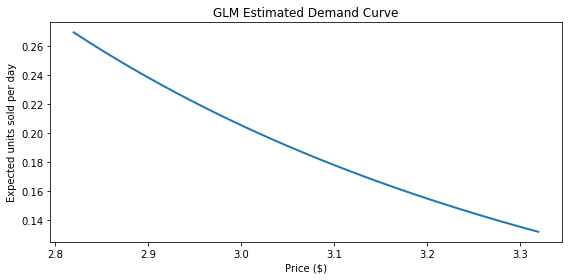

As the price increases, demand decreases.


In [15]:
# plot estimated demand against price
plt.figure(figsize=(8, 4))

plt.plot(
    demand_results['price'].to_numpy(),
    demand_results['predicted_units'].to_numpy(),
    linewidth=2
)

plt.xlabel('Price ($)')
plt.ylabel('Expected units sold per day')
plt.title('GLM Estimated Demand Curve')
plt.tight_layout()
plt.show()

print('As the price increases, demand decreases.')

In [16]:
# find the price with the highest predicted revenue
best_revenue = demand_results.loc[
    demand_results['predicted_revenue'].idxmax()
]

print(f"Revenue-maximizing price: ${best_revenue['price']:.2f}")
print(f"Expected units per day: {best_revenue['predicted_units']:.2f}")
print(f"Expected revenue per day: ${best_revenue['predicted_revenue']:.2f}")
      
results_dict['Generalized Linear'] = {
'median_historical_price': current_price,
'revenue_maximizing_price': best_revenue['price'],
'predicted_units_per_day': best_revenue['predicted_units'],
'predicted_revenue_per_day': best_revenue['predicted_revenue']
} 

Revenue-maximizing price: $2.82
Expected units per day: 0.27
Expected revenue per day: $0.76


# Model demand with calculus

In [20]:
import sympy as sp
import numpy as np

# define price as a positive variable
price = sp.symbols('price', positive=True)

# define the baseline demand constant and price elasticity
baseline_demand, elasticity = sp.symbols(
    'baseline_demand elasticity', real=True
)

# define expected demand under the poisson glm's log-link
# baseline_demand represents baseline demand, while elasticity controls the
# proportional response of demand to a proportional change in price
demand = baseline_demand * price**elasticity

# define total revenue as price multiplied by expected demand
revenue = price * demand

# differentiate revenue with respect to price using calculus
# the derivative measures how revenue changes as price changes
marginal_revenue = sp.diff(revenue, price)

# get the estimated price elasticity from the fitted poisson glm
estimated_elasticity = float(model_demand.params['log_price'])

# set the derivative equal to zero and solve for price
critical_price = sp.solve(
    sp.Eq(marginal_revenue.subs(elasticity, estimated_elasticity), 0),
    price
)

# display the solution
print(f"Estimated price elasticity: {estimated_elasticity:.3f}")
print(f"Revenue function: {revenue}")
print(f"Revenue derivative: {marginal_revenue}")
print(f"Critical price: {critical_price}")

Estimated price elasticity: -4.392
Revenue function: baseline_demand*price*price**elasticity
Revenue derivative: baseline_demand*elasticity*price**elasticity + baseline_demand*price**elasticity
Critical price: []


Critical price: [] = SymPy found no price that makes the derivative equal zero.  
Interpretation: the model predicts that revenue decreases as price increases, so the revenue-maximizing price within a tested price range is its lowest price.  
This agrees with our findings above.

In [21]:
# determine the tested price range
price_min = df['sell_price'].quantile(0.10)
price_max = df['sell_price'].quantile(0.90)

# select the revenue-maximizing price implied by the derivative
if estimated_elasticity < -1:
    calculus_price = price_min
elif estimated_elasticity > -1:
    calculus_price = price_max
else:
    calculus_price = current_price

# predict demand at the selected price
test = df.copy()
test['log_price'] = np.log(calculus_price)

# ensure calendar variables match the model's training data
test['month'] = test['date'].dt.month
test['weekday'] = test['date'].dt.dayofweek

calculus_units = model_demand.predict(test).mean()
calculus_revenue = calculus_price * calculus_units

# save the calculus results
results_dict['The Calculus'] = {
    'median_historical_price': current_price,
    'revenue_maximizing_price': calculus_price,
    'predicted_units_per_day': calculus_units,
    'predicted_revenue_per_day': calculus_revenue
}

# display results
print(f"Revenue-maximizing price: ${calculus_price:.2f}")
print(f"Expected units per day: {calculus_units:.2f}")
print(f"Expected revenue per day: ${calculus_revenue:.2f}")

Revenue-maximizing price: $2.82
Expected units per day: 0.27
Expected revenue per day: $0.76


# Results
Calculus analytically determines the revenue-maximizing price using the GLM’s estimated price elasticity, providing a mathematical check on the GLM’s price recommendation. Furthermore, in this example, The Calculus model is built on the GL model. This explains why the results are the same.


Next step would be understanding the impact on cost, revenue, and profit.

In [22]:
display(pd.DataFrame(results_dict).T)

,median_historical_price,revenue_maximizing_price,predicted_units_per_day,predicted_revenue_per_day
Log-Demand,3.02,2.830204,0.154421,0.437043
Generalized Linear,3.02,2.820000,0.269614,0.760310
The Calculus,3.02,2.820000,0.269614,0.760310


In [19]:
print('done')

done
